## Implementation of Linear regression using python

In [10]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt


## Load the dataset

In [11]:
DF1=pd.read_csv("weight-height.csv")
DF1.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


### Standardize numerical features

In [19]:
col=["Height","Weight"]
S1=MinMaxScaler()
DF1[col]=S1.fit_transform(DF1[col])
DF1.head()


,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [22]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
X.shape
Y.shape

(10000, 1)

## Split the data into training and test set

In [23]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [24]:
# Create a linear regression model

model=LinearRegression()



Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [34]:
## Training  Linear regressions model 

In [25]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [36]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.0044380478890116955
0.066618675227084
0.05448015043349376
0.8135299373473702
[3.54709605]
[0.10829265]


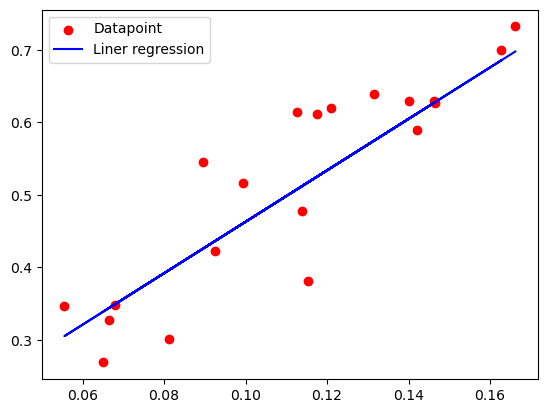

In [37]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [38]:
## Load the Height and weight  to indipendent and dependent variable 

In [26]:
df2=pd.read_csv("weight-height.csv")
X=df2['Height'].values.reshape(-1,1)
X.shape
Y=df2['Weight'].values
print(X.shape)
print(Y.shape)

(10000, 1)
(10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [27]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [30]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [33]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)
print(y_pred.shape)

(10000, 2)
(2, 10000)
(10000,)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [40]:
for i in range(iterations):
    y_pred=np.dot(X,theta)
    mse= mean_squared_error(Y,y_pred)
    mseh.append(mse)
    print(f"Iteration {i+1}: MSE={mse}")
    gradient = np.dot(X.T, (y_pred - Y))/ len(Y)
    theta -= learningrate * gradient

Iteration 1: MSE=0.2869054926644623
Iteration 2: MSE=0.2869054926380145
Iteration 3: MSE=0.286905492612093
Iteration 4: MSE=0.2869054925866874
Iteration 5: MSE=0.2869054925617874
Iteration 6: MSE=0.28690549253738273
Iteration 7: MSE=0.28690549251346387
Iteration 8: MSE=0.28690549249002095
Iteration 9: MSE=0.2869054924670446
Iteration 10: MSE=0.28690549244452535
Iteration 11: MSE=0.28690549242245433
Iteration 12: MSE=0.2869054924008225
Iteration 13: MSE=0.28690549237962115
Iteration 14: MSE=0.2869054923588417
Iteration 15: MSE=0.28690549233847573
Iteration 16: MSE=0.2869054923185151
Iteration 17: MSE=0.2869054922989517
Iteration 18: MSE=0.2869054922797775
Iteration 19: MSE=0.286905492260985
Iteration 20: MSE=0.2869054922425664
Iteration 21: MSE=0.28690549222451434
Iteration 22: MSE=0.2869054922068215
Iteration 23: MSE=0.2869054921894808
Iteration 24: MSE=0.28690549217248507
Iteration 25: MSE=0.28690549215582767
Iteration 26: MSE=0.2869054921395017
Iteration 27: MSE=0.28690549212350064
I

ValueError: x and y must have same first dimension, but have shapes (1000,) and (1002,)

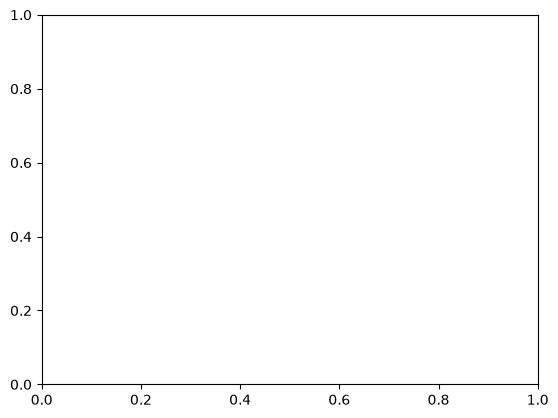

In [39]:
# Plot the MSE over iterations
plt.plot(range(iterations), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()

## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

### Solution: Linear regression on Food_Delivery_Times dataset

#### Step 1: Load the dataset and inspect it

In [2]:
df=pd.read_csv("Food_Delivery_Times.csv")
print(df.shape)
display(df.head())
print(df.isnull().sum())

(1000, 9)


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64


#### Step 2: Feature selection and handling missing values
Select the four independent variables (`Distance_km`, `Preparation_Time_min`, `Traffic_Level`, `Weather`) and the target `Delivery_Time_min`. Rows with missing values in these columns are removed.

In [3]:
features=["Distance_km","Preparation_Time_min","Traffic_Level","Weather"]
target="Delivery_Time_min"
data=df[features+[target]].dropna().reset_index(drop=True)
print("Rows after dropping missing values:",data.shape[0])
print(data["Traffic_Level"].unique(), data["Weather"].unique())

Rows after dropping missing values: 940
<StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str <StringArray>
['Windy', 'Clear', 'Foggy', 'Rainy', 'Snowy']
Length: 5, dtype: str


#### Step 3: Categorical encoding
- **Traffic_Level** is *ordinal* (Low < Medium < High), so it is label/ordinal encoded: Low=0, Medium=1, High=2.
- **Weather** is *nominal* (no natural order), so it is one-hot encoded (`drop_first=True` avoids the dummy variable trap).

In [4]:
data["Traffic_Level"]=data["Traffic_Level"].map({"Low":0,"Medium":1,"High":2})
data=pd.get_dummies(data,columns=["Weather"],drop_first=True,dtype=int)
data.head()

,Distance_km,Preparation_Time_min,Traffic_Level,Delivery_Time_min,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy
0,7.93,12,0,43,0,0,0,1
1,16.42,20,1,84,0,0,0,0
2,9.52,28,0,59,1,0,0,0
3,7.44,5,1,37,0,1,0,0
4,19.03,16,0,68,0,0,0,0


#### Step 4: Prepare independent (X) and dependent (Y) variables

In [5]:
X=data.drop(columns=[target])
Y=data[target]
print(X.shape,Y.shape)
print(list(X.columns))

(940, 7) (940,)
['Distance_km', 'Preparation_Time_min', 'Traffic_Level', 'Weather_Foggy', 'Weather_Rainy', 'Weather_Snowy', 'Weather_Windy']


#### Step 5: Split into training and test sets

In [6]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=67)
print(X_train.shape,X_test.shape)

(752, 7) (188, 7)


#### Step 6: Scale the numerical features
The scaler is fitted on the training data only to avoid data leakage.

In [7]:
num_cols=["Distance_km","Preparation_Time_min"]
scaler=MinMaxScaler()
X_train_s=X_train.copy(); X_test_s=X_test.copy()
X_train_s[num_cols]=scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols]=scaler.transform(X_test[num_cols])
X_train_s.head()

,Distance_km,Preparation_Time_min,Traffic_Level,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy
160,0.182990,0.375000,1,0,0,0,0
718,0.770103,0.875000,0,1,0,0,0
272,0.079381,0.166667,0,0,1,0,0
351,0.990206,0.083333,2,0,0,0,0
103,0.876289,0.791667,0,0,0,0,0


#### Step 7: Train the Linear Regression model

In [8]:
model=LinearRegression()
model.fit(X_train_s,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


#### Step 8: Evaluate the model (MSE, RMSE, MAE, R²)

In [9]:
Y_pred=model.predict(X_test_s)
mse=mean_squared_error(Y_test,Y_pred)
rmse=mse**0.5
mae=mean_absolute_error(Y_test,Y_pred)
r2=r2_score(Y_test,Y_pred)
print("MSE :",mse)
print("RMSE:",rmse)
print("MAE :",mae)
print("R2  :",r2)
print("\nIntercept:",model.intercept_)
print(pd.DataFrame({"Feature":X_train_s.columns,"Coefficient":model.coef_}))

MSE : 103.23564385516657
RMSE: 10.16049427218807
MAE : 6.4913999653827315
R2  : 0.7684391491317988

Intercept: 7.709187353222937
                Feature  Coefficient
0           Distance_km    58.645544
1  Preparation_Time_min    24.596475
2         Traffic_Level     5.686159
3         Weather_Foggy     9.479077
4         Weather_Rainy     5.817250
5         Weather_Snowy    10.387406
6         Weather_Windy     2.754203


#### Step 9: Visualize the results

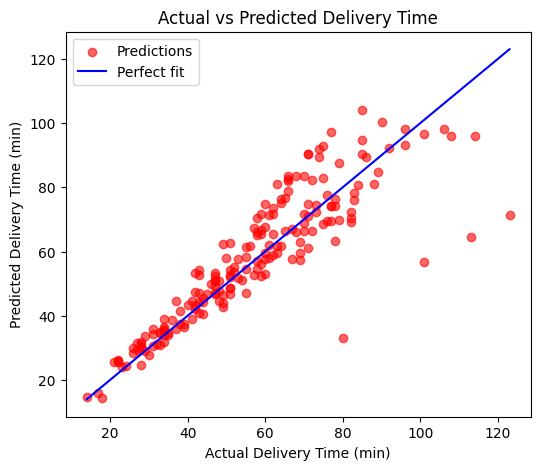

In [10]:
plt.figure(figsize=(6,5))
plt.scatter(Y_test,Y_pred,color="red",alpha=0.6,label="Predictions")
lims=[Y_test.min(),Y_test.max()]
plt.plot(lims,lims,color="blue",label="Perfect fit")
plt.xlabel("Actual Delivery Time (min)")
plt.ylabel("Predicted Delivery Time (min)")
plt.title("Actual vs Predicted Delivery Time")
plt.legend()
plt.show()

In [11]:
# Predict delivery time for a new order: 10 km, 15 min prep, High traffic, Rainy weather
new=pd.DataFrame([{c:0 for c in X_train_s.columns}])
new["Distance_km"]=10; new["Preparation_Time_min"]=15; new["Traffic_Level"]=2
if "Weather_Rainy" in new.columns: new["Weather_Rainy"]=1
new[num_cols]=scaler.transform(new[num_cols])
print("Predicted delivery time (min):",model.predict(new)[0])

Predicted delivery time (min): 63.593399406537635


#### Conclusion
A multiple linear regression model was fitted to predict `Delivery_Time_min` from `Distance_km`, `Preparation_Time_min`, `Traffic_Level` (ordinal encoded) and `Weather` (one-hot encoded). The coefficients show how much each factor changes the delivery time, and the R² score shows how much of the variation in delivery time the model explains.